# 1. NN or ANN

NN - Neural Network

ANN - Artifacial Neural Network


---------------

NN — Neural Network
The general term for a network of connected (neurons) that learns patterns from data.

- Examples include ANN, CNN, and RNN.

------------

ANN — Artificial Neural Network
A general artificial neural network, often referring to a fully connected feedforward network, also called an MLP (Multilayer Perceptron).


- Commonly used for tabular data.
- Can perform classification and regression.
- Example: predicting customer churn from age, revenue, and number of lines.

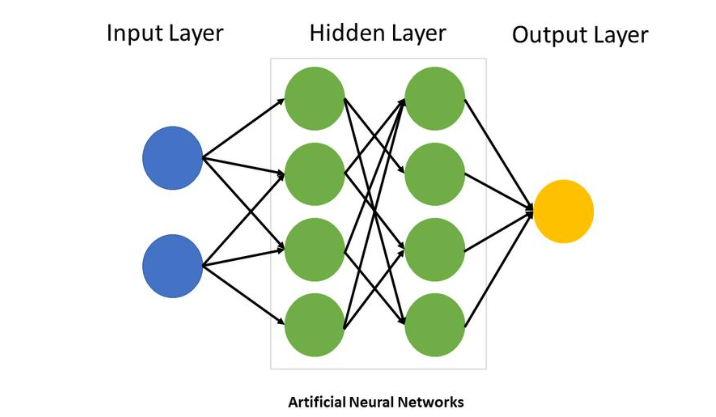

------------

# 2. CNN ( Convolutional Neural Network )

A neural network architecture that uses convolution operations to learn local patterns and spatial features.
- Mainly used for images and spatial data.
- Can perform classification, regression, and segmentation.
- Example: classifying an image as a cat or a dog.

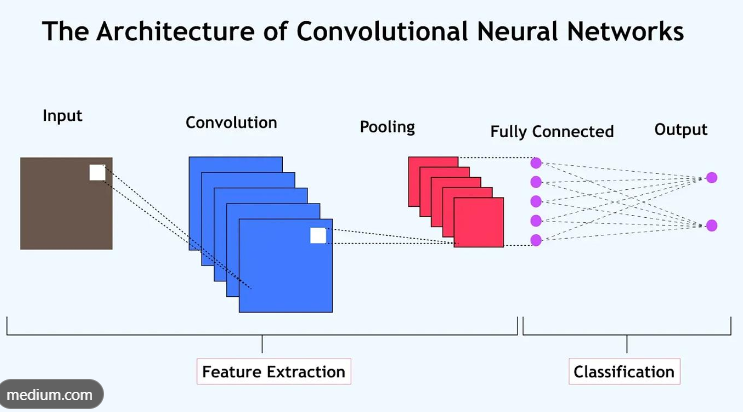

----------

# 3. RNN - Recurrent Neural Network

A neural network architecture designed to process sequences, using information from previous time steps.

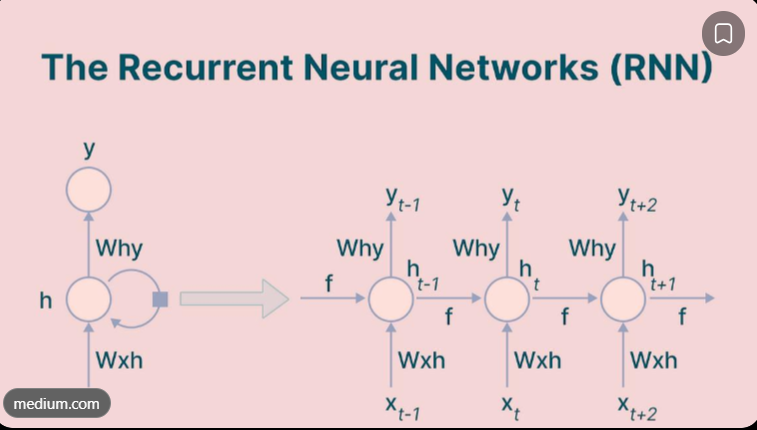

------------

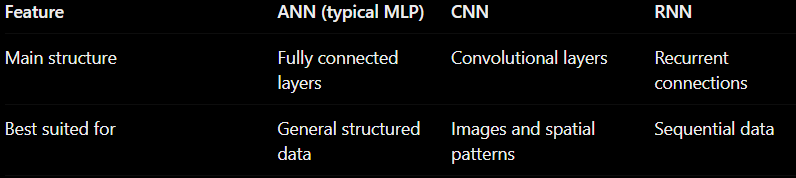
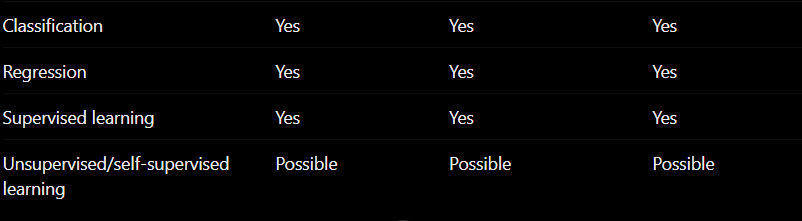

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OrdinalEncoder
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import PolynomialFeatures
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LinearRegression
from sklearn.linear_model import Ridge, Lasso
from sklearn.neighbors import KNeighborsRegressor
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import CategoricalNB
from sklearn.naive_bayes import BernoulliNB
from sklearn.naive_bayes import MultinomialNB
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC # svm => SVC , SVR
from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
from sklearn.ensemble import RandomForestClassifier


from sklearn import metrics
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer



#--------------------------

from sklearn.neural_network import MLPClassifier


Telco Customer Churn Prediction

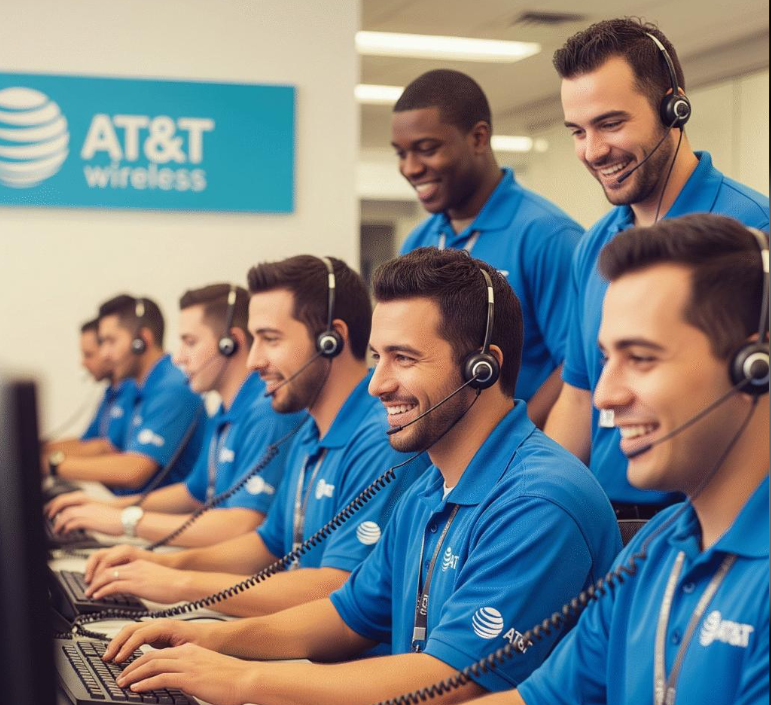

In [ ]:
df=pd.read_csv("/content/WA_Fn-UseC_-Telco-Customer-Churn.csv")

In [ ]:
df.head(2)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No


In [ ]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

Problem type: Binary Classification.



Learning type: Supervised Learning.



Model: Artificial Neural Network — MLPClassifier.



Target: Churn (Yes / No).

In [ ]:
print(df["Churn"].value_counts())

Churn
No     5174
Yes    1869
Name: count, dtype: int64


In [ ]:
print("Missing values:")
print(df.isnull().sum())

print("Duplicate rows:", df.duplicated().sum())

Missing values:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64
Duplicate rows: 0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [ ]:
# i need to convert the text to numbers

df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce" # عشان أي قيمة غير قابلة للتحويل لرقم تتحول إلى NaN بدل ما يحصل Error.
)

print(df["TotalCharges"].isnull().sum())


11


In [ ]:
df["TotalCharges"] = df["TotalCharges"].fillna(0)

In [ ]:
# drop unique columns
df = df.drop(columns=["customerID"])

In [ ]:
X = df.drop(columns=["Churn"])

y = df["Churn"].replace({
    "No": 0,
    "Yes": 1
})

print(y.value_counts())

Churn
0    5174
1    1869
Name: count, dtype: int64


/tmp/ipykernel_410/3422871303.py:3: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  y = df["Churn"].replace({


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


In [ ]:
# Identify feature types
numeric_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

In [ ]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

In [ ]:
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

In [ ]:
preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

In [ ]:
# Fit and transform training data
X_train_final = preprocessor.fit_transform(X_train)
X_test_final = preprocessor.transform(X_test)
# Keep target unchanged
y_train_final = y_train

####ANN

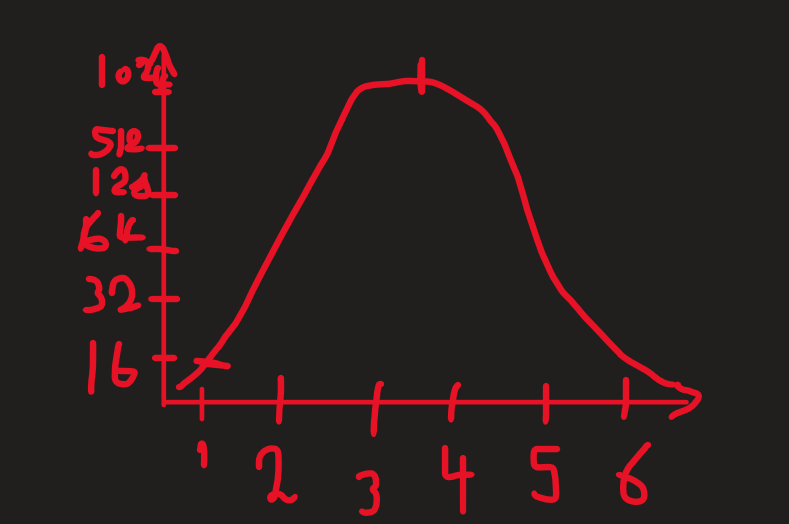

In [ ]:
from sklearn.neural_network import MLPClassifier

# Create the Neural Network
ann = MLPClassifier(
    hidden_layer_sizes=(8,128,68,32,8),
    random_state=42,
    max_iter=500, # أقصى عدد من Iterations للتدريب
    early_stopping=True # يوقف التدريب مبكرًا لو أداء الـ Validation لم يتحسن
)

# 7. Train the model
ann.fit(X_train_final, y_train_final)

MLPClassifier(early_stopping=True, hidden_layer_sizes=(8, 128, 68, 32, 8),
              max_iter=500, random_state=42)

In [ ]:
y_test_pred = ann.predict(X_test_final)

accuracy_score(y_test, y_test_pred)

0.8019872249822569

In [ ]:
ann.score(X_test_final,y_test)

0.8019872249822569

Score()

 بتعمل Predictions داخليًا

وتقارنها بالإجابات الحقيقية
  
   وترجع الـ Accuracy مباشرةً.

#Save the Model

In [ ]:
import joblib
import os

os.makedirs("models", exist_ok=True)

joblib.dump(ann, "models/telco_churn_ann.joblib")

print("Model saved successfully!")

Model saved successfully!


#Load the Model

In [ ]:
# Example customer
new_customer = pd.DataFrame([{
    "gender": "Female",
    "SeniorCitizen": 0,
    "Partner": "No",
    "Dependents": "No",
    "tenure": 2,
    "PhoneService": "Yes",
    "MultipleLines": "No",
    "InternetService": "Fiber optic",
    "OnlineSecurity": "No",
    "OnlineBackup": "No",
    "DeviceProtection": "No",
    "TechSupport": "No",
    "StreamingTV": "Yes",
    "StreamingMovies": "Yes",
    "Contract": "Month-to-month",
    "PaperlessBilling": "Yes",
    "PaymentMethod": "Electronic check",
    "MonthlyCharges": 85.0,
    "TotalCharges": 170.0
}])


In [ ]:
loaded_model = joblib.load("models/telco_churn_ann.joblib")

# Preprocess the raw customer data first
new_customer_final = preprocessor.transform(new_customer)

prediction = loaded_model.predict(new_customer_final)[0]

print(prediction)

Prediction: Churn


------------------------

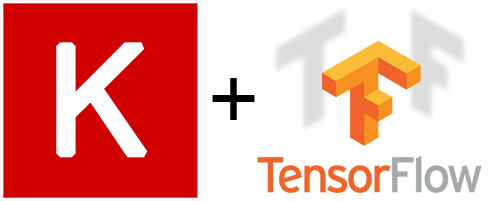

Tensorflow -- Framework / engine

keras -- high level api / UI

In [ ]:
import tensorflow as tf

In [ ]:
model = tf.keras.models.Sequential([
    tf.keras.layers.Dense(16, activation='relu'),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dense(1, activation='sigmoid')
])

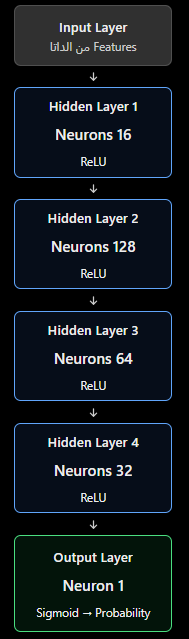

In [ ]:
# baghz el model la el training
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

NameError: name 'model' is not defined

Loss Function

1. binary_crossentropy - Churn/Not Churn

2. categorical_crossentropy - Cat/Dog /Bird

3. sparse_categorical_crossentropy -	Classes = 0, 1, 2

4. mean_squared_error (MSE)

5. mean_absolute_error (MAE)



```
# Binary Classification
loss = "binary_crossentropy"

# Multiclass: One-Hot Labels
loss = "categorical_crossentropy"

# Multiclass: Integer Labels
loss = "sparse_categorical_crossentropy"

# Regression
loss = "mean_squared_error"
loss = "mean_absolute_error"

# Regression with outliers
loss = tf.keras.losses.Huber()

# Imbalanced binary classification
loss = tf.keras.losses.BinaryFocalCrossentropy()
```

In [ ]:
# 3. Train the model
history = model.fit(
    X_train_final,
    y_train,
    epochs=50,
    batch_size=32,
    validation_split=0.2
)

Epoch 1/50
141/141 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.7708 - loss: 0.4679 - val_accuracy: 0.7897 - val_loss: 0.4481
Epoch 2/50
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8019 - loss: 0.4274 - val_accuracy: 0.7870 - val_loss: 0.4413
Epoch 3/50
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8112 - loss: 0.4147 - val_accuracy: 0.7879 - val_loss: 0.4491
Epoch 4/50
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8101 - loss: 0.4115 - val_accuracy: 0.7844 - val_loss: 0.4399
Epoch 5/50
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8118 - loss: 0.4069 - val_accuracy: 0.7870 - val_loss: 0.4464
Epoch 6/50
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8112 - loss: 0.4034 - val_accuracy: 0.7853 - val_loss: 0.4500
Epoch 7/50
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8145 - loss: 0.4030 - val_accuracy: 0.7870 - val_loss: 0.4419
Epoch 8/50
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8178 - loss: 0.3968 - val_accuracy: 0.

In [ ]:
test_loss, test_accuracy = model.evaluate(
    X_test_final,
    y_test,
    verbose=0
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

# 12. Predict
y_pred_prob = model.predict(X_test_final, verbose=0)

y_pred = (y_pred_prob.ravel() >= 0.5).astype("int32")


Test Loss: 0.7742440104484558
Test Accuracy: 0.7615330219268799


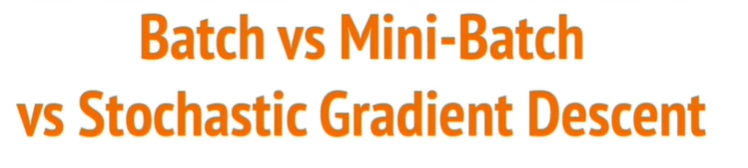

#  Batch & Stochastic & Mini-Batch Gradient Descent

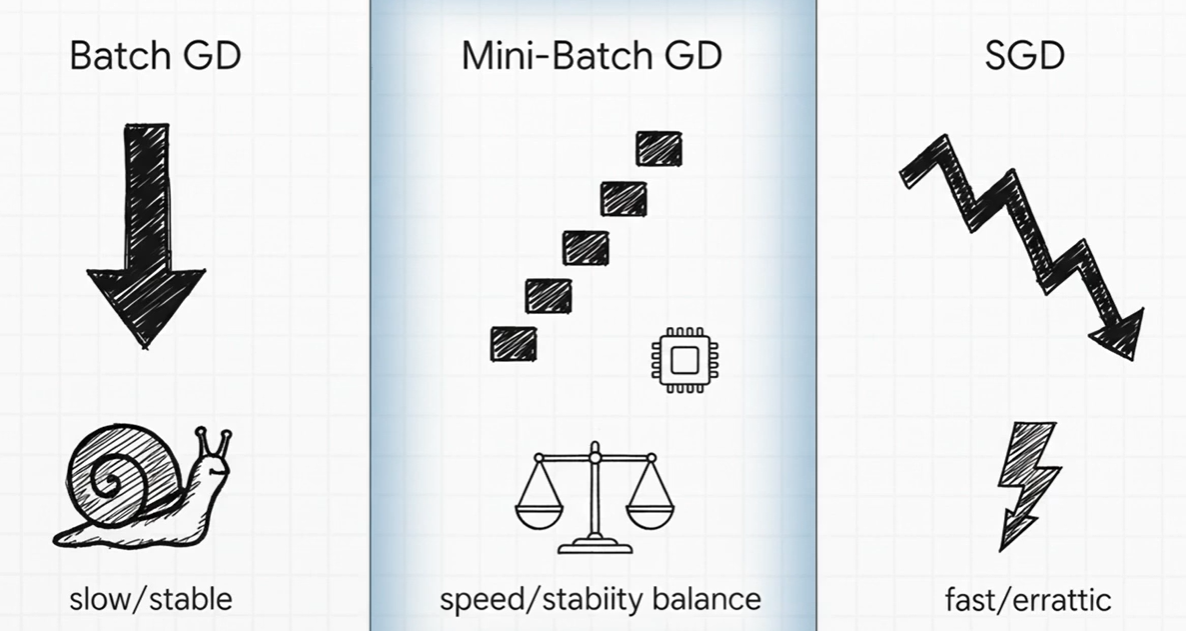

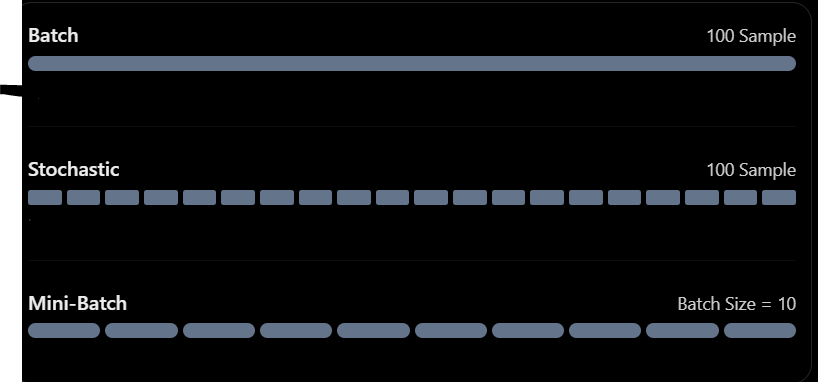

Batch Gradient Descent

In [ ]:
model.compile(
    optimizer="sgd",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

history = model.fit(
    X_train_final,
    y_train,
    epochs=50,
    batch_size=len(X_train_final)
)

Stochastic Gradient Descent

In [ ]:
model.compile(
    optimizer="sgd",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

history = model.fit(
    X_train_final,
    y_train,
    epochs=50,
    batch_size=1
)

Mini-Batch Gradient Descent

In [ ]:
model.compile(
    optimizer="sgd",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

history = model.fit(
    X_train_final,
    y_train,
    epochs=50,
    batch_size=32
)

-----------------------

#Example 2

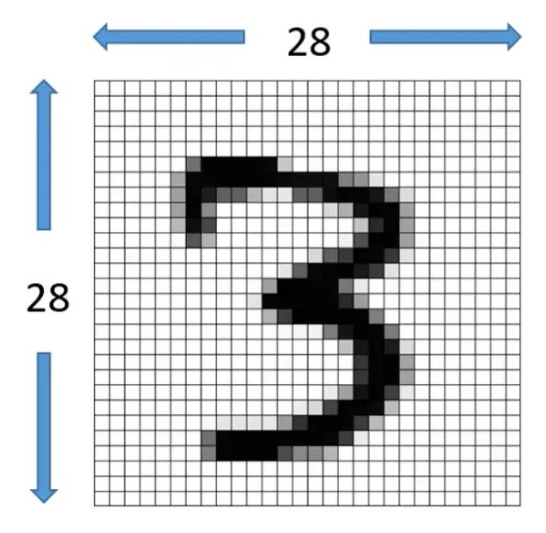

number of images = 70k

training data = 60k

testing data = 10k

size image = 28*28

type image = gray scale


problem = multi-class classification

number classes = 10

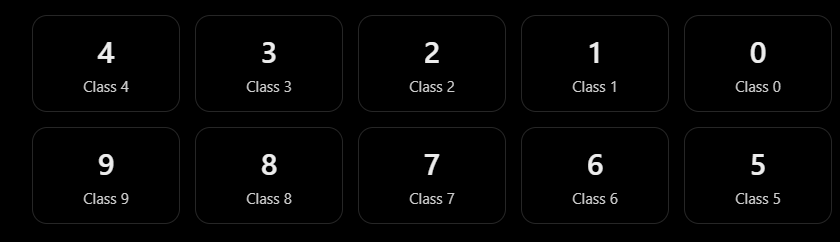

In [ ]:
pip install tensorflow

In [ ]:
from keras.datasets import mnist

In [ ]:
(X_train, y_train), (X_test, y_test) = mnist.load_data()

In [ ]:
(X_train, y_train), (X_test, y_test)

((array([[[0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0],
          ...,
          [0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0]],
  
         [[0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0],
          ...,
          [0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0]],
  
         [[0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0],
          ...,
          [0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0]],
  
         ...,
  
         [[0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0],
          ...,
          [0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0]],
  
         [[0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0

In [ ]:
X_train.shape

(60000, 28, 28)

# Visualize a sample image

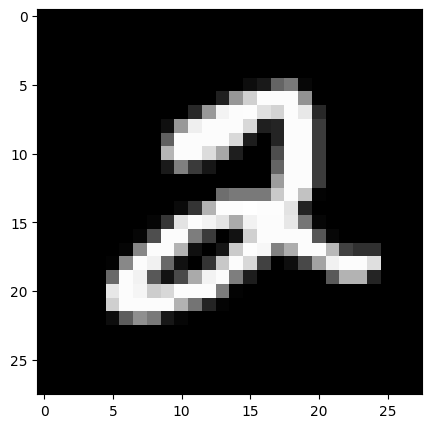

In [ ]:
# Visualize a sample image
plt.figure(figsize=(5, 5))
plt.imshow(X_train[5], cmap='gray')


# Flatten for images

convert 2d array to vector

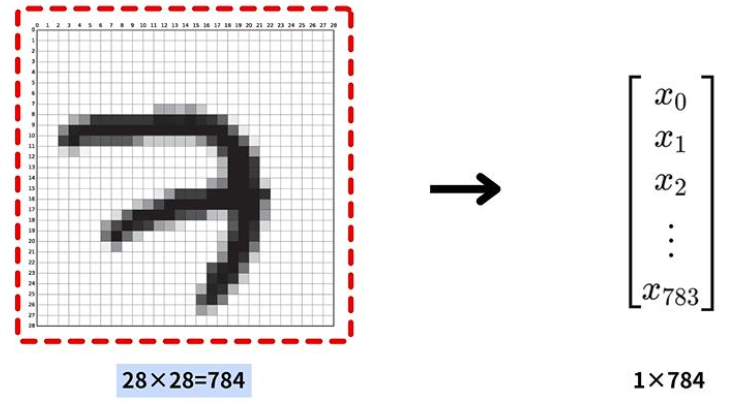

```
X_train.shape
(60000, 28, 28)
   ⬇ ⬇
(60000, 784)   
```



In [ ]:
# Flatten and Normalize the images
X_train = X_train.reshape(-1, 784) / 255
X_test = X_test.reshape(-1, 784) / 255


notes

 1. -1 -- numpy claculate number of Row

2. divide 255

grayscale & pixel

[0, 0, 0, 128, 255, 200, 0, ...]

by divide 255

grayscale --

[0, 0, 0, 0.502, 1.0, 0.784, 0, ...]



In [ ]:
X_train.shape, y_train.shape, X_test.shape, y_test.shape


((60000, 784), (60000,), (10000, 784), (10000,))

(0,255)

 ⏬ ⏬

(0,1)

In [ ]:
X_train.min(), X_train.max(), X_test.min(), X_test.max()


(np.float64(0.0), np.float64(1.0), np.float64(0.0), np.float64(1.0))

In [ ]:
X_train[0]

array([0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.     

In [ ]:
y_train[0]


np.uint8(5)

## Keras model

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.utils import to_categorical


In [ ]:
# Convert labels to categorical one-hot encoding
y_train = to_categorical(y_train)
y_test = to_categorical(y_test)


```
0	[1,0,0,0,0,0,0,0,0,0]
3	[0,0,0,1,0,0,0,0,0,0]
5	[0,0,0,0,0,1,0,0,0,0]
9	[0,0,0,0,0,0,0,0,0,1]
```

In [ ]:
y_train.shape, y_test.shape


((60000, 10), (10000, 10))

In [ ]:
y_train[0]


array([0., 0., 0., 0., 0., 1., 0., 0., 0., 0.])

## Build the model

In [ ]:
model = Sequential([
    Dense(64, activation='relu', input_shape=(784,)),
    Dense(64, activation='relu'),
    Dense(10, activation='softmax')
])

In [ ]:
# Compile the model.
model.compile(optimizer='Adam', loss='categorical_crossentropy',
              metrics=['accuracy'])

In [ ]:
# Model summary.
model.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_12 (Dense)                │ (None, 64)             │        50,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 55,050 (215.04 KB)

 Trainable params: 55,050 (215.04 KB)

 Non-trainable params: 0 (0.00 B)

frist hidden layer

data 784 (28*28)

Neuron 64

bias 64

784*64+64 = 50,240

In [ ]:
model.fit(X_train,
          y_train,
          epochs=10,
          batch_size=32)

Epoch 1/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9215 - loss: 0.2734
Epoch 2/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9632 - loss: 0.1216
Epoch 3/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9731 - loss: 0.0889
Epoch 4/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9782 - loss: 0.0696
Epoch 5/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.9826 - loss: 0.0561
Epoch 6/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9847 - loss: 0.0481
Epoch 7/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9873 - loss: 0.0397
Epoch 8/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9892 - loss: 0.0340
Epoch 9/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9903 - loss: 0.0294
Epoch 10/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9918 - loss: 0.0253


In [ ]:
model.evaluate(X_test, y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9730 - loss: 0.1072


[0.10723668336868286, 0.9729999899864197]

## without onehotencoder

In [ ]:
# Build the model.
model = Sequential([
    Dense(64, activation='relu', input_shape=(784,)),
    Dense(64, activation='relu'),
    Dense(10, activation='softmax')
])

# Compile the model.
model.compile(optimizer='Adam', loss="sparse_categorical_crossentropy",
              metrics=['accuracy'])

# Train the model.
model.fit(X_train, y_train, epochs=10, batch_size=32)
print("Training complete.\n")




Epoch 1/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9198 - loss: 0.2759
Epoch 2/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9625 - loss: 0.1248
Epoch 3/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9721 - loss: 0.0921
Epoch 4/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9774 - loss: 0.0721
Epoch 5/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9814 - loss: 0.0582
Epoch 6/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9844 - loss: 0.0486
Epoch 7/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9859 - loss: 0.0424
Epoch 8/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9881 - loss: 0.0365
Epoch 9/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9897 - loss: 0.0303
Epoch 10/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9909 - loss: 0.0276
Training complete.

Evaluating the model on test data...
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9741 - 

[0.09920202195644379, 0.9740999937057495]

In [ ]:
# Evaluate the model.
print("Evaluating the model on test data...")
model.evaluate(X_test, y_test)


Evaluating the model on test data...
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9741 - loss: 0.0992


[0.09920202195644379, 0.9740999937057495]

--------------

```
model = Sequential()
model.add(Dense(64, activation='relu', input_shape=(784,)))
model.add(Dense(64, activation='relu'))
model.add(Dense(10, activation='softmax'))
```

```
from tensorflow.keras.layers import Activation
model = Sequential()
model.add(Dense(64, input_dim=784))
model.add(Activation('relu'))
model.add(Dense(64))
model.add(Activation('relu'))
model.add(Dense(10))
model.add(Activation('softmax'))
```

```
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input
inputs = Input(shape=(784,))
x = Dense(64, activation='relu')(inputs)
x = Dense(64, activation='relu')(x)
predictions = Dense(10, activation='softmax')(x)
model = Model(inputs=inputs, outputs=predictions)
```

-------------

In [ ]:
checkpoint = tf.keras.callbacks.ModelCheckpoint(
    filepath="best_model.h5",
    monitor="val_loss",
    save_best_only=True,
    mode="min"
)

In [ ]:
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

In [ ]:
history = model.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=32,
    validation_split=0.2,
    callbacks=[checkpoint,early_stop]
)

Epoch 1/50
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9966 - loss: 0.0102 - val_accuracy: 0.9838 - val_loss: 0.0789
Epoch 2/50
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9984 - loss: 0.0050 - val_accuracy: 0.9858 - val_loss: 0.0732
Epoch 3/50
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9967 - loss: 0.0100 - val_accuracy: 0.9862 - val_loss: 0.0719
Epoch 4/50
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9976 - loss: 0.0076 - val_accuracy: 0.9834 - val_loss: 0.0799
Epoch 5/50
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9973 - loss: 0.0077 - val_accuracy: 0.9820 - val_loss: 0.0968
Epoch 6/50
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9973 - loss: 0.0082 - val_accuracy: 0.9837 - val_loss: 0.0820
Epoch 7/50
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9976 - loss: 0.0072 - val_accuracy: 0.9825 - val_loss: 0.1013
Epoch 8/50
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9976 - loss: 0.0073 - 